In [7]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import netCDF4 as nc
import os

def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=1):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [3]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

/tmp/ipykernel_663668/3192702059.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_663668/3192702059.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


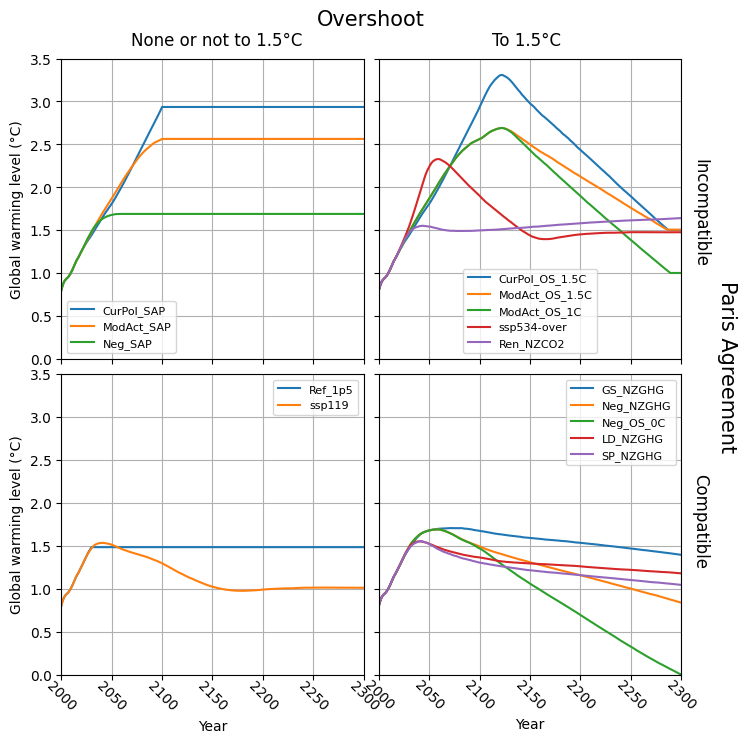

In [10]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
axs[0,0].set_ylim(0,3.5)
for s in scenarios:
    # if PA_compliant(temps = df[s]):
    #     col = 'green'
    # else:
    #     col = 'red'
    # if OS_ref(df[s].to_numpy()):
    #     ls='-'
    # else: 
    #     ls = '--'
    temp=df[s].to_numpy()
    axs[int(PA_compliant(temp)), int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), df[s], label=s)

for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Global warming level (°C)')

# axs[1,0].tick_params(axis='x',labelrotation=+45)
axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['None or not to 1.5°C', 'To 1.5°C'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
# fig.tight_layout()
# axs[1,0].set_xticks([2000,2050,2100,2150,2200,2250])

# Simulations with Armstrong Mckay thresholds

In [13]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='Sheet1')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [16]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

In [18]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|███████████████████████████████████████| 450/450 [00:00<00:00, 9716.98it/s]


In [19]:
D.shape

(15, 500, 9, 451)

/tmp/ipykernel_663668/1677428942.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_663668/1677428942.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


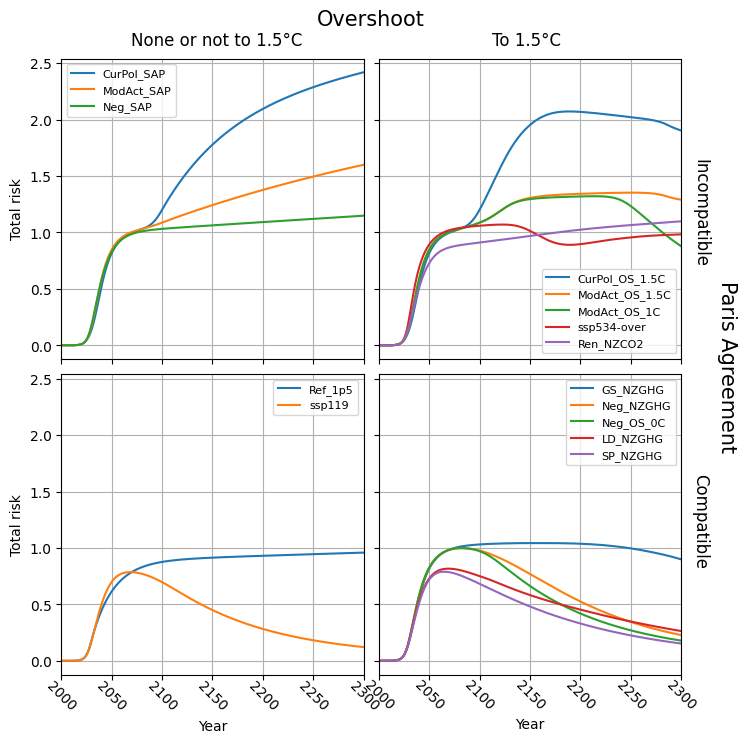

In [27]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        D[i,:,:,:].mean(axis=0).sum(axis=0), label=s)
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Total risk')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['None or not to 1.5°C', 'To 1.5°C'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

# Simulations with GTPR25 thresholds

In [28]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='Sheet1')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [29]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

In [30]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|███████████████████████████████████████| 450/450 [00:00<00:00, 8976.17it/s]


/tmp/ipykernel_663668/434242871.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_663668/434242871.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


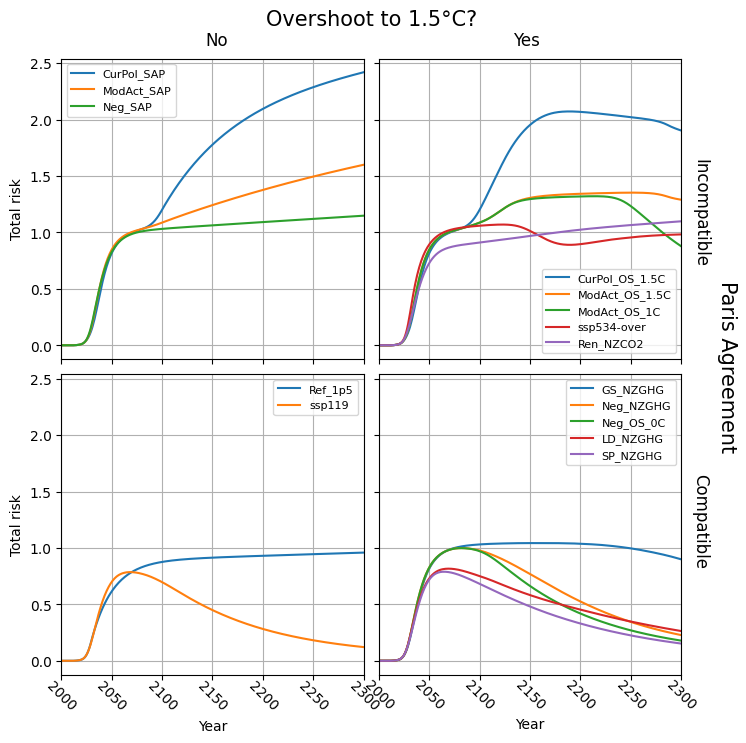

In [38]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        D[i,:,:,:].mean(axis=0).sum(axis=0), label=s)
    # util.plot.ribbon_plot(axs[int(PA_compliant(moving_avg(temp))), 
    #     int(OS_ref(temp,ref=1.5))], 
    #                       years, D[i,:,:,:].sum(axis=1), axis=0, color='red',shade=[1],alpha=[0.3],label=[''])
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Total risk')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

In [45]:
TEs=df_TEs.index.values
print(TEs)

['AMAZ' 'AMOC' 'ASI' 'ENSO' 'GIS' 'PERM' 'REEF' 'WAIS' 'WAM']


In [43]:
np.where(TEs=='AMAZ')[0][0]

np.int64(0)

/tmp/ipykernel_663668/2742633137.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_663668/2742633137.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


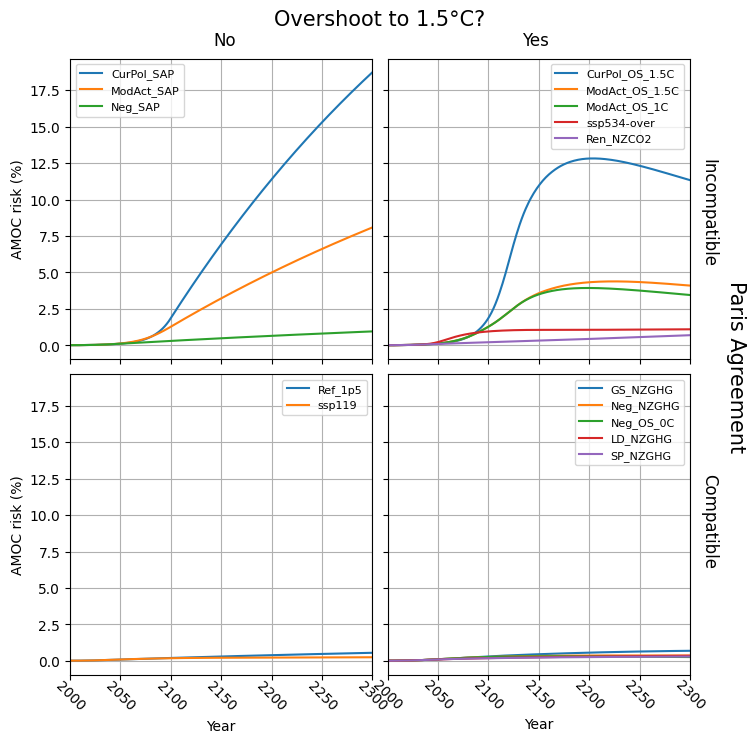

In [61]:
TE= 'AMOC'
te_ind = np.where(TEs==TE)[0][0]
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        D[i,:,te_ind,:].mean(axis=0)*100, label=s)
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel(TE+' risk (%)')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")